# Paso 8 · Exploración de FER2013

Objetivo: **conocer el dataset antes de entrenar nada**: cuántas imágenes hay por clase, cómo son, qué calidad tienen y qué emociones se parecen entre sí.

Usamos 6 clases: **enfado, miedo, feliz, neutral, triste y sorpresa**. *Disgust* se descarta por tener muy pocas muestras.

## Cómo obtener el dataset
Elige **una** opción en la celda de configuración (`ORIGEN`):

| `ORIGEN` | Cuándo usarlo | Qué hace |
|---|---|---|
| `"local"` | Tienes el dataset descomprimido en tu PC | Lo lee de `RUTA_LOCAL` |
| `"drive"` | Ejecutas en **Google Colab** con el `.zip` en tu Google Drive | Monta Drive, copia el zip a Colab y lo descomprime |
| `"kaggle"` | No lo tienes (p. ej. el profesor) | Lo descarga de Kaggle (`msambare/fer2013`) con `kagglehub` |

Estructura esperada (dentro de la carpeta raíz):
```
train/  angry/ disgust/ fear/ happy/ neutral/ sad/ surprise/
test/   (las mismas carpetas)
```

In [ ]:
# ===================== CONFIGURACIÓN =====================
ORIGEN = "kaggle"                       # "local" | "drive" | "kaggle"

RUTA_LOCAL = "../data/fer2013"            # carpeta con train/ y test/ (relativa al notebook)
ZIP_EN_DRIVE = "/content/drive/MyDrive/VC/fer2013.zip"   # solo si ORIGEN = "drive"
# =========================================================

from pathlib import Path
import random
import numpy as np
import cv2
import matplotlib.pyplot as plt

# Clases que usamos (sin disgust) y su nombre en el catálogo de Pokémon
CLASES = {"angry": "enfado", "fear": "miedo", "happy": "feliz",
          "neutral": "neutral", "sad": "triste", "surprise": "sorpresa"}

random.seed(0)        # semilla fija -> resultados reproducibles
np.random.seed(0)

## Localizar el dataset
La función `buscar_raiz` busca, dentro de la carpeta indicada, la subcarpeta que contiene `train/` y `test/`. Así da igual si al descomprimir se crea una carpeta extra por medio.

**Nota sobre Drive:** leer 35.000 archivos sueltos directamente desde Drive es *muy* lento. Por eso, en modo `"drive"`, se copia el `.zip` a Colab y se descomprime allí (`/content/fer2013`), que es mucho más rápido.

In [3]:
def buscar_raiz(carpeta):
    # Devuelve la carpeta que contiene train/ y test/ (puede estar un nivel o dos más abajo)
    carpeta = Path(carpeta)
    for candidata in [carpeta, *carpeta.glob("*"), *carpeta.glob("*/*")]:
        if (candidata / "train").is_dir() and (candidata / "test").is_dir():
            return candidata
    raise FileNotFoundError(f"No encuentro train/ y test/ dentro de {carpeta.resolve()}")

if ORIGEN == "local":
    RAIZ = buscar_raiz(RUTA_LOCAL)

elif ORIGEN == "drive":
    import zipfile, shutil
    from google.colab import drive
    drive.mount("/content/drive")
    destino = Path("/content/fer2013")
    if not destino.exists():
        shutil.copy(ZIP_EN_DRIVE, "/content/fer2013.zip")
        with zipfile.ZipFile("/content/fer2013.zip") as z:
            z.extractall(destino)
    RAIZ = buscar_raiz(destino)

elif ORIGEN == "kaggle":
    # Requiere:  pip install kagglehub
    # Si pide credenciales: crea un token en kaggle.com > Settings > API y guarda kaggle.json
    import kagglehub
    RAIZ = buscar_raiz(kagglehub.dataset_download("msambare/fer2013"))

else:
    raise ValueError("ORIGEN debe ser 'local', 'drive' o 'kaggle'")

print("Dataset en:", RAIZ.resolve())

c:\Users\becha\anaconda3\envs\VC_P5\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 60.3M/60.3M [00:02<00:00, 26.9MB/s]

Extracting files...


Dataset en: C:\Users\becha\.cache\kagglehub\datasets\msambare\fer2013\versions\1


## Lectura de imágenes
`cv2.imread` falla en Windows si la ruta tiene caracteres como la **ñ** (`4año_1semestre`). Por eso Python lee los bytes (`np.fromfile`) y OpenCV solo los decodifica (`cv2.imdecode`), el mismo truco que en `leer_png` del filtro.

In [4]:
def leer_gris(ruta):
    datos = np.fromfile(str(ruta), dtype=np.uint8)
    return cv2.imdecode(datos, cv2.IMREAD_GRAYSCALE)

def rutas_de(split, clase):
    return sorted((RAIZ / split / clase).glob("*"))

## 1. ¿Cuántas imágenes hay de cada clase?

In [5]:
conteo = {}
for split in ["train", "test"]:
    print(f"--- {split} ---")
    for carpeta in sorted((RAIZ / split).iterdir()):
        if not carpeta.is_dir():
            continue
        n = len(list(carpeta.glob("*")))
        usada = "" if carpeta.name in CLASES else "   (descartada)"
        print(f"  {carpeta.name:10s} {n:6d}{usada}")
        conteo[(split, carpeta.name)] = n

n_train = sum(conteo[("train", c)] for c in CLASES)
n_test = sum(conteo[("test", c)] for c in CLASES)
print(f"\nTotal (6 clases): train={n_train}  test={n_test}  -> test = {100 * n_test / (n_train + n_test):.1f}% del total")

--- train ---
  angry        3995
  disgust       436   (descartada)
  fear         4097
  happy        7215
  neutral      4965
  sad          4830
  surprise     3171
--- test ---
  angry         958
  disgust       111   (descartada)
  fear         1024
  happy        1774
  neutral      1233
  sad          1247
  surprise      831

Total (6 clases): train=28273  test=7067  -> test = 20.0% del total


## 2. Desequilibrio entre clases
Si una clase tiene muchas más imágenes, el modelo tiende a "apostar" por ella. Lo tendremos en cuenta al entrenar (p. ej. con `class_weight="balanced"` en la SVM).

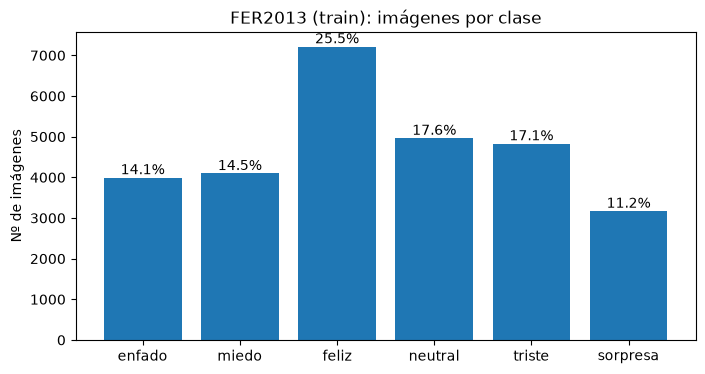

Ratio clase mayor / clase menor: 2.28


In [6]:
nombres = list(CLASES)
train = [conteo[("train", c)] for c in nombres]

plt.figure(figsize=(8, 4))
barras = plt.bar([CLASES[c] for c in nombres], train)
for b, n in zip(barras, train):
    plt.text(b.get_x() + b.get_width() / 2, n, f"{100 * n / sum(train):.1f}%", ha="center", va="bottom")
plt.title("FER2013 (train): imágenes por clase")
plt.ylabel("Nº de imágenes")
plt.show()

print(f"Ratio clase mayor / clase menor: {max(train) / min(train):.2f}")

## 3. Ejemplos de cada clase
Fíjate en la **calidad**: ¿hay imágenes sin cara, con texto, dibujos, de perfil o que parecen mal etiquetadas?

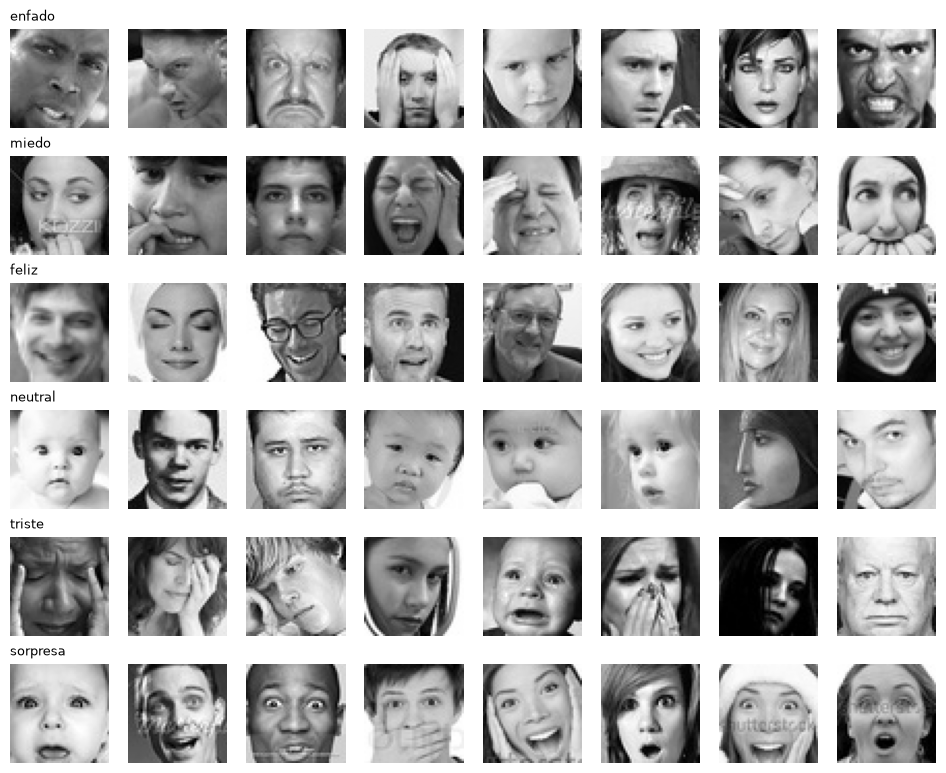

In [7]:
N = 8
fig, ejes = plt.subplots(len(CLASES), N, figsize=(N * 1.2, len(CLASES) * 1.3))
for fila, clase in enumerate(CLASES):
    for col, ruta in enumerate(random.sample(rutas_de("train", clase), N)):
        ejes[fila, col].imshow(leer_gris(ruta), cmap="gray")
        ejes[fila, col].axis("off")
    ejes[fila, 0].set_title(CLASES[clase], loc="left", fontsize=9)
plt.tight_layout()
plt.show()

## 4. Formato de las imágenes
**Importante para el paso 11:** la cara de la webcam tendrá que quedar exactamente en este formato antes de pasársela al modelo.

In [8]:
ejemplo = leer_gris(rutas_de("train", "happy")[0])
print("Forma:", ejemplo.shape, "| Tipo:", ejemplo.dtype, "| Min/Max:", ejemplo.min(), ejemplo.max())

# Comprobación rápida de que TODAS tienen el mismo tamaño (muestra de 300 por clase)
tamanos = {leer_gris(r).shape for c in CLASES for r in rutas_de("train", c)[:300]}
print("Tamaños encontrados:", tamanos)

Forma: (48, 48) | Tipo: uint8 | Min/Max: 0 255
Tamaños encontrados: {(48, 48)}


## 5. La "cara media" de cada emoción
Media píxel a píxel de 500 caras por clase, la misma idea que la cara media de las **autocaras** (`VC_P5_eigenfaces`). Fíjate en **boca y cejas**: son las zonas que diferencian las emociones.

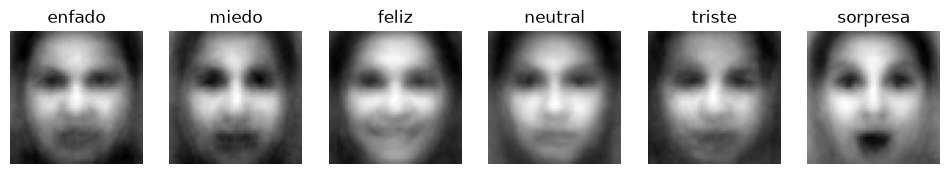

In [9]:
medias = {}
fig, ejes = plt.subplots(1, len(CLASES), figsize=(len(CLASES) * 2, 2.4))
for i, clase in enumerate(CLASES):
    medias[clase] = np.mean([leer_gris(r).astype(np.float32) for r in rutas_de("train", clase)[:500]], axis=0)
    ejes[i].imshow(medias[clase], cmap="gray")
    ejes[i].set_title(CLASES[clase])
    ejes[i].axis("off")
plt.show()

## 6. ¿En qué se diferencia cada emoción de la neutral?
Restamos la cara media *neutral* a cada una: en rojo, zonas más claras que en neutral; en azul, más oscuras. Muestra **dónde cambia la cara** con cada emoción.

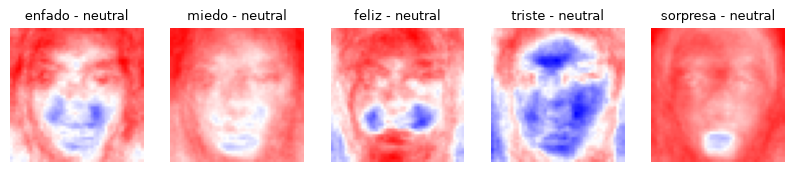

In [10]:
otras = [c for c in CLASES if c != "neutral"]
fig, ejes = plt.subplots(1, len(otras), figsize=(len(otras) * 2, 2.4))
for i, clase in enumerate(otras):
    dif = medias[clase] - medias["neutral"]
    lim = np.abs(dif).max()
    ejes[i].imshow(dif, cmap="bwr", vmin=-lim, vmax=lim)
    ejes[i].set_title(f"{CLASES[clase]} - neutral", fontsize=9)
    ejes[i].axis("off")
plt.show()

## Preguntas para la memoria
- **a)** ¿Qué clase tiene más imágenes y cuál menos? ¿Cuántas veces más? ¿Cómo crees que afectará al modelo?
- **b)** ¿Has visto imágenes raras (sin cara, texto, dibujos, perfil, mal etiquetadas)? → *ruido en las etiquetas*.
- **c)** Según las caras medias y las diferencias, ¿qué emociones se parecen más? Apuesta cuáles confundirá el modelo (lo comprobaremos en el paso 10).
- **d)** ¿Qué porcentaje del total es `test`?